# Medical Insurance Cost Prediction - Linear Regression

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

### Task 1 – Load the Dataset

In [2]:
df = pd.read_csv("insurance.csv")
print(df.shape)
print(df.columns.tolist())
df.head()

(1338, 7)
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Task 2 – Identify Variables

In [3]:
X = df[["age"]]
y = df["charges"]
print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (1338, 1)
y shape: (1338,)


,age
0,19
1,18
2,28
3,33
4,32


### Task 3 – Data Visualization

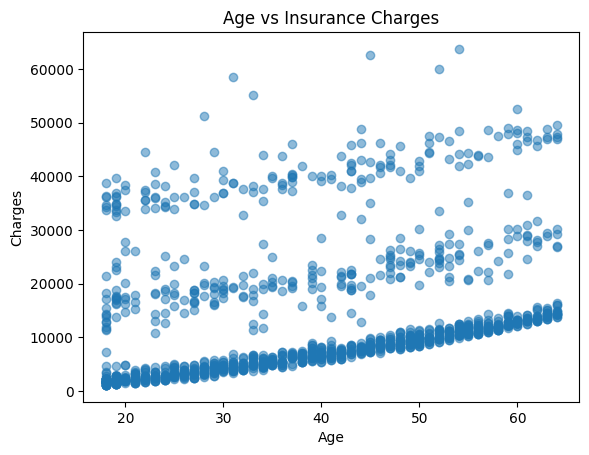

In [4]:
plt.scatter(df["age"], df["charges"], alpha=0.5)
plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Charges")
plt.show()

**Observation:**
Looking at the scatter plot, insurance charges generally go up as age increases. There are also distinct groups or bands in the points, which suggests other factors like smoking or health conditions also have a big effect on the charges.

### Task 4 – Split the Data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1070, 1)
X_test: (268, 1)


### Task 5 – Train the Model

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 240.59655978877493
Intercept: 3876.928684191691


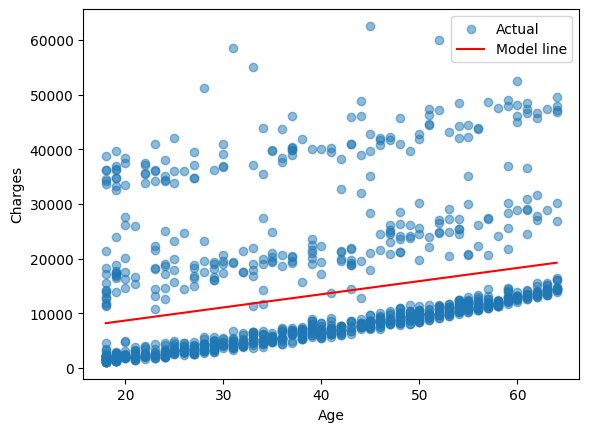

In [7]:
pred_train = model.predict(X_train)
order = np.argsort(X_train["age"].values)
plt.scatter(X_train["age"], y_train, label="Actual", alpha=0.5)
plt.plot(
    X_train["age"].values[order],
    pred_train[order],
    color="red",
    label="Model line"
)
plt.xlabel("Age")
plt.ylabel("Charges")
plt.legend()
plt.show()

### Task 6 – Make Predictions

In [8]:
pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
})
results.head(10)

,Actual,Predicted
0,9095.06825,14703.773875
1,5272.17580,12538.404837
2,29330.98315,19275.108511
3,9301.89355,14944.370434
4,33750.29180,8448.263320
5,4536.25900,12057.211717
6,2117.33885,8448.263320
7,14210.53595,19275.108511
8,3732.62510,10613.632358
9,10264.44210,15666.160114


### Task 7 – Evaluate the Model

In [9]:
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print("MAE:", mae)
print("R2 Score:", r2)

MAE: 9173.258196746589
R2 Score: 0.12408973539501944


### Final Questions

**1. Does insurance cost increase with age?**  
Yes, it does. Both the scatter plot and the positive slope of around 240 show that older people generally pay more. Roughly, each additional year of age adds about 240 dollars to the cost.

**2. Which features might influence insurance charges?**  
Besides age, other features in the dataset like smoker status, BMI, and the number of children heavily influence the charges. Smoking in particular makes a huge difference.

**3. How close are the predicted values to the actual values?**  
They follow the general upward line, but because we only used age, the predictions are not very close for individuals. The MAE is around 9,135, which means predictions are off by quite a bit because the model doesn't know if someone is a smoker or has a high BMI.

**4. Is your model performing reasonably well? Explain briefly.**  
It works as a simple baseline to show the age trend, but an R2 of around 0.12 means age only explains about 12% of the change in charges. It needs more features like smoker and BMI to make good predictions.

**5. Where can this model be used in real life?**  
An insurance company could use it to get a quick rough estimate of costs based on age, and regular people could use it to understand how their insurance costs might increase over time as they get older.